### **Filters and Effects**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jrafa1607/Computer_Vision_In_Python/blob/main/Algorithms/Filters_and_Effects.ipynb)

> Filters change each pixel based on its neighborhood (**spatial filters**) or on its own value (**intensity transformations**). This notebook covers mirroring, sharpening with a **high-pass filter**, smoothing with **low-pass filters**, negative and **gamma** transformations, and measures how well each smoothing filter removes **salt-and-pepper noise** using the PSNR.

In [1]:
# Import libraries and helpers (images load from ../Images locally, or from GitHub in Colab)
import os
import urllib.request

import cv2
import numpy as np
from matplotlib import pyplot as plt

BASE_URL = "https://raw.githubusercontent.com/jrafa1607/Computer_Vision_In_Python/main/Images/"

def load_image(name, flags=cv2.IMREAD_COLOR):
    """Returns the image in OpenCV format (BGR for color images)."""
    local = os.path.join("..", "Images", name)
    if os.path.exists(local):
        data = np.fromfile(local, np.uint8)
    else:
        with urllib.request.urlopen(BASE_URL + name) as response:
            data = np.frombuffer(response.read(), np.uint8)
    return cv2.imdecode(data, flags)

def show(images, titles, size=(14, 4)):
    """Shows images side by side; color images are converted from BGR to RGB for Matplotlib."""
    fig, axes = plt.subplots(1, len(images), figsize=size)
    for ax, image, title in zip(np.atleast_1d(axes), images, titles):
        if image.ndim == 3:
            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

In [2]:
# Load the image
img = load_image("astronaut.png")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

#### **01. Mirroring**

Flipping reverses the order of rows or columns: `cv2.flip(img, 1)` mirrors left to right, `0` top to bottom, and `-1` both.

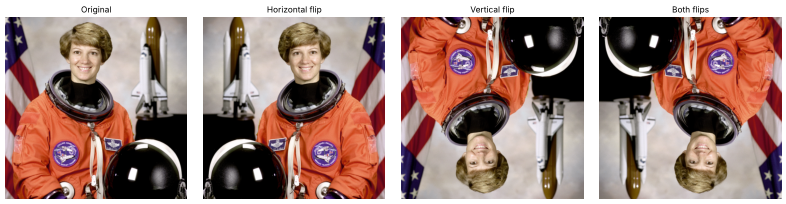

In [3]:
# Horizontal, vertical, and both flips
show([img, cv2.flip(img, 1), cv2.flip(img, 0), cv2.flip(img, -1)],
     ["Original", "Horizontal flip", "Vertical flip", "Both flips"], size=(16, 4))

#### **02. High-Pass Filter (Sharpening)**

A high-pass kernel such as `[[-1,-1,-1],[-1,8,-1],[-1,-1,-1]]` keeps rapid intensity changes (edges and fine details). Adding this response to the original sharpens the image. The filter must run in floating point: in 8-bit arithmetic, negative responses are clipped to 0 and half of each edge is lost.

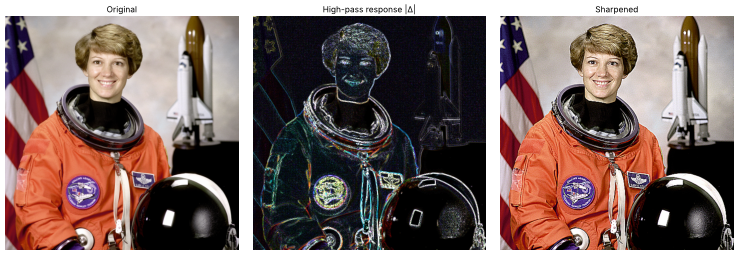

In [4]:
# High-pass response computed in float, then added back for sharpening
kernel = np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]], np.float32)
high_pass = cv2.filter2D(img.astype(np.float32), -1, kernel)
sharpened = np.clip(img.astype(np.float32) + 0.5 * high_pass, 0, 255).astype(np.uint8)
edges_view = np.clip(np.abs(high_pass), 0, 255).astype(np.uint8)
show([img, edges_view, sharpened], ["Original", "High-pass response |Δ|", "Sharpened"], size=(15, 5))

#### **03. Smoothing Filters (Low-Pass) and Noise Removal**

* **Mean:** average of the neighborhood; simple, but blurs edges.
* **Gaussian:** weighted average that favors closer pixels.
* **Median:** the middle value of the neighborhood; ideal for impulsive (salt-and-pepper) noise because outliers never reach the output.
* **Bilateral:** averages only pixels with similar intensity, preserving edges.

The **PSNR** (peak signal-to-noise ratio, in dB) compares each result with the clean image: higher is better.

Noisy (5%)     PSNR =  17.5 dB
Mean 5x5       PSNR =  24.4 dB
Gaussian 5x5   PSNR =  25.4 dB
Median 5x5     PSNR =  27.9 dB
Bilateral      PSNR =  17.6 dB


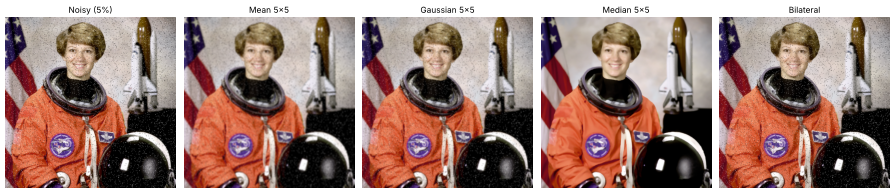

In [5]:
# Add salt-and-pepper noise (seeded, so the result is reproducible)
def add_salt_pepper(image, amount, seed=42):
    rng = np.random.default_rng(seed)
    noisy = image.copy()
    mask = rng.random(image.shape[:2])
    noisy[mask < amount / 2] = 0          # pepper
    noisy[mask > 1 - amount / 2] = 255    # salt
    return noisy

noisy = add_salt_pepper(img, 0.05)
filters = {
    "Mean 5x5": cv2.blur(noisy, (5, 5)),
    "Gaussian 5x5": cv2.GaussianBlur(noisy, (5, 5), 0),
    "Median 5x5": cv2.medianBlur(noisy, 5),
    "Bilateral": cv2.bilateralFilter(noisy, 9, 75, 75),
}
print(f"{'Noisy (5%)':<14} PSNR = {cv2.PSNR(img, noisy):5.1f} dB")
for name, result in filters.items():
    print(f"{name:<14} PSNR = {cv2.PSNR(img, result):5.1f} dB")
show([noisy] + list(filters.values()), ["Noisy (5%)"] + list(filters), size=(18, 4))

#### **04. Intensity Transformations**

* **Negative:** `255 - pixel` inverts the tones.
* **Gamma (power law):** `255 * (pixel / 255) ** gamma`. A gamma below 1 brightens dark tones; above 1 darkens them. A lookup table applies it to the 256 possible values at once.

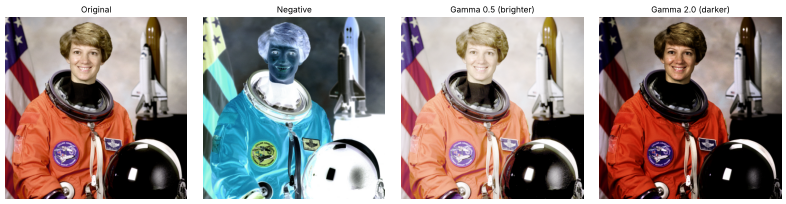

In [6]:
# Negative and gamma correction with a lookup table
def apply_gamma(image, gamma):
    table = (255 * (np.arange(256) / 255) ** gamma).round().astype(np.uint8)
    return cv2.LUT(image, table)

show([img, 255 - img, apply_gamma(img, 0.5), apply_gamma(img, 2.0)],
     ["Original", "Negative", "Gamma 0.5 (brighter)", "Gamma 2.0 (darker)"], size=(16, 4))

#### **Key Takeaways**

* Compute filters with negative coefficients in floating point, then clip back to 0–255.
* The median filter clearly wins against salt-and-pepper noise, as the PSNR shows. The bilateral filter barely helps: it treats the isolated specks as edges and preserves them.
* Seed random noise so the results can be reproduced and compared.